# Project 1: executed experiment evidence

**Kevin Yang (ky2738), Team Saber**

[Public GitHub source](https://github.com/Solvement/26-Deep-Learning-Project-1-Kaggle/tree/feat/cifar10-resnet-submission)

This notebook reads measured artifacts; it does not replace training logs with expected accuracy. The separate training entrypoint contains the main scratch-training implementation. The public-feedback-driven robust_full extension is exploratory and is reported separately. Private leaderboard accuracy is not yet available.

In [1]:
from pathlib import Path
import json, sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the cloned project or its notebooks directory.')
sys.path.insert(0, str(ROOT))
from runtime import configure_runtime
configure_runtime()
from build_report import collect_evidence, choose_run, accuracy, public_accuracy, val_accuracy, checkpoint_details, measured_interpretation
evidence = collect_evidence(ROOT / 'results')
selected = choose_run(evidence, 'final_full')
print('Team: Saber | Kevin Yang | ky2738')
print('Recorded runs:', [run['name'] for run in evidence['runs']])
print('Selected run:', selected['name'] if selected else 'Pending')

Team: Saber | Kevin Yang | ky2738
Recorded runs: ['baseline', 'architecture', 'regularized', 'final_full']
Selected run: final_full


## Architecture and parameter-budget check
A fresh CPU construction matches the selected saved architecture configuration (default WRN-22-4 until a selection is available) and independently checks its parameter count. It does not load a pretrained or external model.

In [2]:
from model import build_model, count_parameters
config = selected['config'] if selected else {}
model_config = {k: config.get(k, v) for k,v in {'depth':22,'widen_factor':4,'dropout':0.0,'num_classes':10}.items()}
model = build_model(model_config)
total = count_parameters(model)
trainable = count_parameters(model, trainable_only=True)
print(model)
print(f'Total parameters: {total:,}')
print(f'Trainable parameters: {trainable:,}')
assert trainable == total
if model_config['depth'] == 22 and model_config['widen_factor'] == 4:
    assert total == 4_298_970
assert total <= 5_000_000
del model

WideResNet(
  (stem): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (stage1): Sequential(
    (0): PreActWideBlock(
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu1): ReLU(inplace=True)
      (conv1): Conv2d(16, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu2): ReLU(inplace=True)
      (dropout): Identity()
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (projection): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    )
    (1): PreActWideBlock(
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu1): ReLU(inplace=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): Bat

## Actual experimental configurations and results
The matched protocol fixes the split, seed, schedule and optimizer. The architecture comparison changes depth and width jointly; the regularization comparison changes Cutout and MixUp jointly. The measured effects below do not establish statistical significance or separate the bundled factors.

### Exploratory robust_full specification
The regularized candidate's development/public accuracies were 96.30%/87.40%; the cause of this gap was not established. The separately scored robust_full benchmark, specified after official public feedback, uses a scratch WRN-22-4 on all 50,000 permitted training images: 300 SGD/cosine epochs, RandAugment N=2/M=9 [6], crop/flip, Cutout and MixUp, the fixed final-epoch EMA checkpoint (decay 0.999), clean-training-only batch-normalization recalibration, and fixed reflect-pad-four five-crop-plus-flip logit averaging. The original 160-epoch study and its confirmation result remain unchanged. This bundled, public-feedback-driven extension has no held-out development score or confirmation re-evaluation and is not a causal ablation. The earlier confirmation accuracy belongs only to the selected 40,000-image candidate. Execution or scoring is claimed only when actual artifacts and official receipts support it.

In [3]:
for run in evidence['runs']:
    print('\nRUN:', run['name'])
    print('CONFIGURATION:', json.dumps(run['config'], indent=2))
    print('METRICS:', json.dumps(run['metrics'], indent=2))
    print('CHECKPOINT AND INFERENCE:', json.dumps(checkpoint_details(run), indent=2))
    print('Epochs recorded:', len(run['history']))
if not evidence['runs']:
    print('Training artifacts are pending.')
for finding in measured_interpretation(evidence):
    print('\nMEASURED FINDING:', finding)


RUN: baseline
CONFIGURATION: {
  "depth": 16,
  "widen_factor": 2,
  "dropout": 0.0,
  "num_classes": 10,
  "epochs": 160,
  "batch_size": 128,
  "lr": 0.1,
  "min_lr": 0.0001,
  "warmup_epochs": 5,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "label_smoothing": 0.0,
  "cutout": 0,
  "mixup_alpha": 0.0,
  "mixup_probability": 0.0,
  "ema_decay": 0.995,
  "seed": 2026,
  "split_seed": 2026,
  "train_all": false,
  "final_variant": "ema",
  "fixed_flip_tta": false
}
METRICS: {
  "status": "complete",
  "epochs_completed": 160,
  "best_validation_accuracy": 0.9424,
  "best_validation_loss": 0.2035413330078125,
  "parameter_count": 691674,
  "elapsed_seconds": 480.1724611000027,
  "training_examples": 40000,
  "validation_examples": 5000,
  "config": {
    "depth": 16,
    "widen_factor": 2,
    "dropout": 0.0,
    "num_classes": 10,
    "epochs": 160,
    "batch_size": 128,
    "lr": 0.1,
    "min_lr": 0.0001,
    "warmup_epochs": 5,
    "momentum": 0.9,
    "weight_decay": 0.0005,
   

In [4]:
exploratory = evidence.get('exploratory', {})
print('EXPLORATORY RUN: robust_full (separate from the primary study)')
print('CONFIGURATION:', json.dumps(exploratory.get('config', {}), indent=2))
print('METRICS:', json.dumps(exploratory.get('metrics', {}), indent=2))
safe_exploratory_keys = ('epoch','variant','parameter_count','validation_examples','validation_accuracy','flip_tta','tta_views','tta_mode','checkpoint_sha256','submission_sha256','bn_recalibrated_on_training_only','exploratory_after_public_feedback','main_confirmation_endorses_this_run')
evaluation = exploratory.get('evaluation', {})
print('FIXED CHECKPOINT AND INFERENCE:', json.dumps({k:evaluation[k] for k in safe_exploratory_keys if k in evaluation}, indent=2))
print('No development or confirmation accuracy is assigned to this full-data exploration.')

EXPLORATORY RUN: robust_full (separate from the primary study)
CONFIGURATION: {
  "depth": 22,
  "widen_factor": 4,
  "dropout": 0.0,
  "num_classes": 10,
  "epochs": 300,
  "batch_size": 128,
  "lr": 0.1,
  "min_lr": 0.0001,
  "warmup_epochs": 5,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "label_smoothing": 0.0,
  "cutout": 16,
  "mixup_alpha": 0.2,
  "mixup_probability": 0.5,
  "ema_decay": 0.999,
  "seed": 3031,
  "split_seed": 2026,
  "train_all": true,
  "final_variant": "ema",
  "randaugment_n": 2,
  "randaugment_m": 9,
  "randaugment_interpolation": "bilinear",
  "randaugment_fill": [
    125,
    123,
    114
  ],
  "checkpoint_interval": 10,
  "tta_mode": "reflectpad4_five_crops_plus_horizontal_flip_mean_logits",
  "exploratory_after_public_feedback": true,
  "confirmation_endorsement": false
}
METRICS: {
  "status": "complete",
  "epochs_completed": 300,
  "parameter_count": 4298970,
  "training_examples": 50000,
  "validation_examples": 0,
  "best_validation_accuracy": n

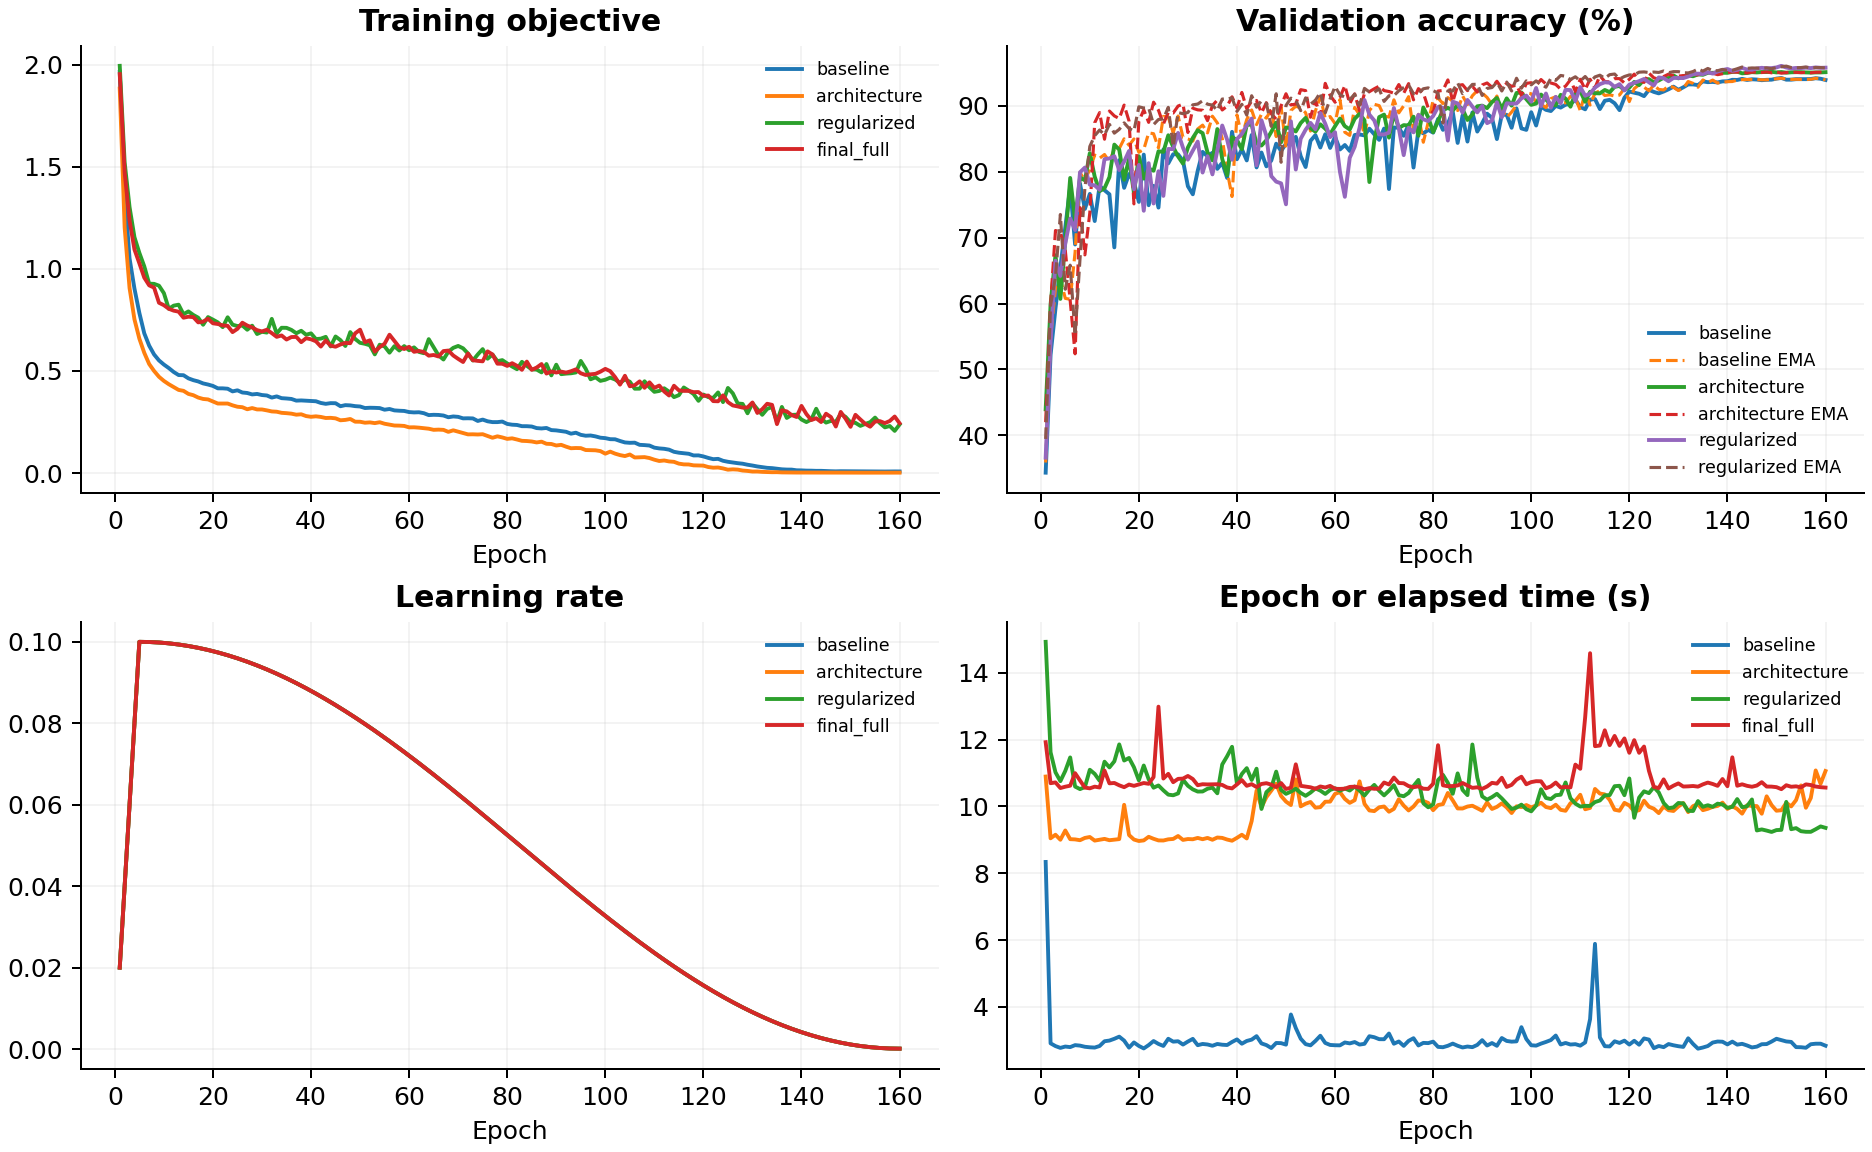

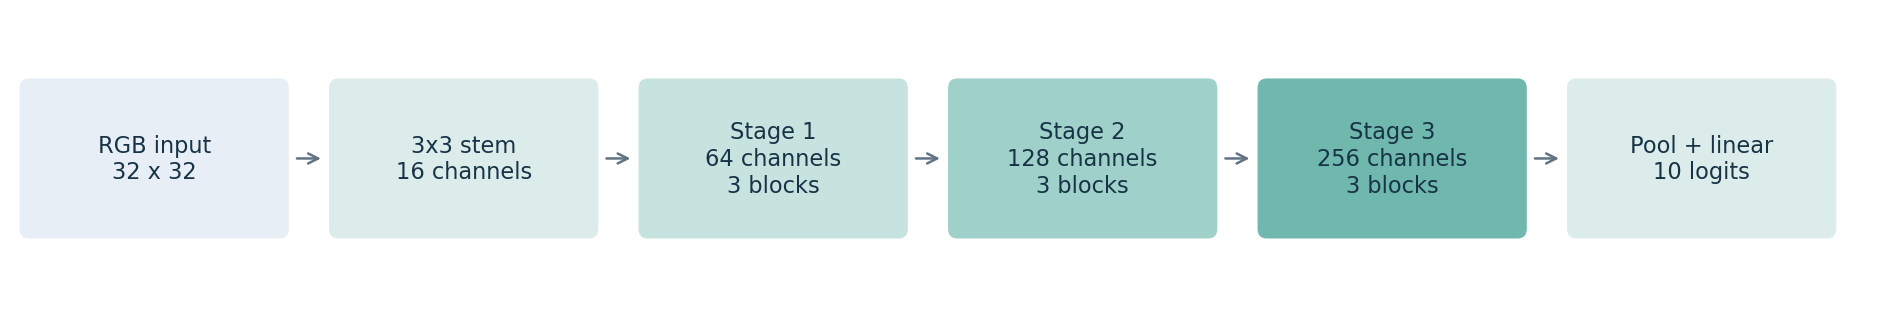

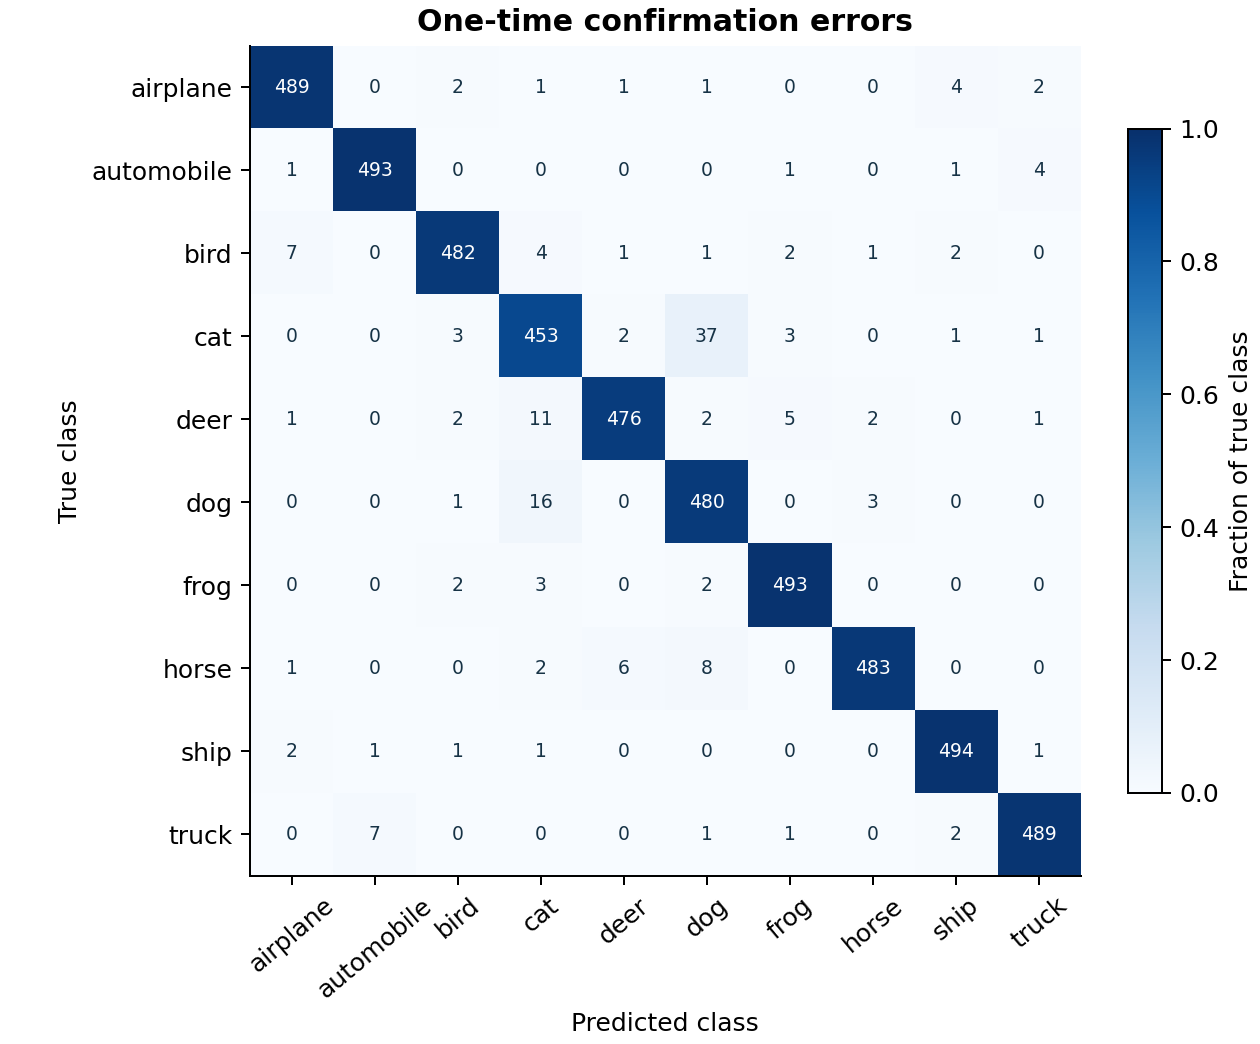

In [5]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/research_report_preview_20261031_a6/learning_curves.png')))
display(Image(filename=str(ROOT / 'outputs/research_report_preview_20261031_a6/architecture.png')))
display(Image(filename=str(ROOT / 'outputs/research_report_preview_20261031_a6/confirmation_confusion.png')))

## Final test accuracy
The public leaderboard measures only half of the 2,000 hidden evaluation images. Development, confirmation, the primary full-data public score and the best observed official benchmark score are distinct. The five-entry plan includes a separately labeled robust_full exploration motivated by official public feedback. Public results may guide entry selection; the main 160-epoch recipe and its confirmation are not changed or repeated. Private accuracy remains unknown.

In [6]:
metrics = selected['metrics'] if selected else {}
if selected and selected['config'].get('train_all'):
    print('Final full-data model validation accuracy: not evaluated (recipe already frozen)')
else:
    print('Development accuracy:', accuracy(checkpoint_details(selected)['development_accuracy']) if selected else 'Pending')
print('One-time confirmation accuracy:', accuracy(evidence['confirmation'].get('accuracy')))
print('Primary full-data test accuracy (Kaggle PUBLIC leaderboard):', accuracy(public_accuracy(evidence['submission'])))
print('Private leaderboard test accuracy: unavailable until released')
print(f'Final model parameter count: {total:,}')
safe_submission_keys = ('submission_ref','public_score','private_score','run','sha256','status','submitted_at','scored_at','commit','source_commit','checkpoint_sha256')
submission_record = {k:evidence['submission'][k] for k in safe_submission_keys if k in evidence['submission']}
print('Primary submission record (scalar fields only):', json.dumps(submission_record, indent=2))
benchmark_keys = ('run','public_score','private_score','submission_ref','submission_sha256','submitted_at','training_examples','parameter_count','flip_tta','status')
print('Official benchmark receipts (scalar fields only):')
for receipt in evidence['submissions']:
    print(json.dumps({k:receipt[k] for k in benchmark_keys if k in receipt}, indent=2))
completed = [r for r in evidence['submissions'] if str(r.get('status','')).lower() == 'complete' and public_accuracy(r) is not None]
if completed:
    best = max(completed,key=public_accuracy)
    print('Highest observed public benchmark:', best.get('run'), accuracy(public_accuracy(best)))
    print('Best public benchmark is not evidence of the unknown private winner.')

Final full-data model validation accuracy: not evaluated (recipe already frozen)
One-time confirmation accuracy: 96.64%
Primary full-data test accuracy (Kaggle PUBLIC leaderboard): 87.10%
Private leaderboard test accuracy: unavailable until released
Final model parameter count: 4,298,970
Primary submission record (scalar fields only): {
  "submission_ref": 57825964,
  "public_score": 0.871,
  "private_score": null,
  "run": "final_full",
  "status": "complete",
  "submitted_at": "2026-10-31T04:09:33.607000+00:00"
}
Official benchmark receipts (scalar fields only):
{
  "run": "baseline",
  "public_score": 0.835,
  "private_score": null,
  "submission_ref": 57825539,
  "submission_sha256": "316af4ad0c3887b6180e8cf2d5b2ac640912d066879986a133fc60f89d6a3e24",
  "submitted_at": "2026-10-31T03:46:44.500000+00:00",
  "training_examples": 40000,
  "parameter_count": 691674,
  "flip_tta": true,
  "status": "complete"
}
{
  "run": "architecture",
  "public_score": 0.854,
  "private_score": null,


## Follow-on research: public reporting snapshot

The original six executed code cells above remain the primary study. These two additional cells read an embedded, allowlisted public aggregate snapshot; they do not load data, checkpoints, individual predictions or private runtime records. The same projection is saved as `research_followup_evidence.json` beside this notebook. The original six cells still require their original private training artifacts to rerun.

All follow-on development results reuse the original development partition. The original study remains frozen. The original 96.64% confirmation belongs only to regularized trained on 40,000 images. That confirmation was not reused. A full-50k refit has no independent development score. Conditional paired intervals describe postselected fitted checkpoints, not independent confirmation or hidden-test accuracy.

SWA [7], SAM [8], CutMix [9], ResizeMix [10] and test-time aggregation [11] are reported only to the extent supported by the measured snapshot. Engineering-only SE candidates [12] remain separate from measured model outcomes.

EXPLORATORY PUBLIC SNAPSHOT: 2026-10-31T21:17:07.553585+00:00
Source-summary SHA-256: b3e06bd38571f484c6d90475437162e8849eb65980e982572deb4e166c022d0d
Public snapshot SHA-256: dbd186271cbf032049687ee601dac47900902715efcbbe1fce7cc16f01b07e43
Research source: https://github.com/Solvement/26-Deep-Learning-Project-1-Kaggle/tree/feat/five-day-autoresearch
Fixed v3 development baseline: {
  "clean_accuracy": 0.9628,
  "clean_nll": 0.1221306333810091,
  "examples": 5000,
  "policy": "flip",
  "stress_accuracy": 0.7762800000000001,
  "training_examples": 40000
}
RESEARCH AGGREGATE: {
  "checkpoint_epoch": 152,
  "checkpoint_sha256": "1787237fb5f4566043843f9008516e911b9a6d867bc6ac4720c52448871c7b9a",
  "checkpoint_variant": "model",
  "clean_accuracy": 0.9632,
  "clean_ci95": [
    -0.004,
    0.0048
  ],
  "clean_delta": 0.00039999999999995595,
  "clean_nll": 0.12463519598171115,
  "delivery_status": "qualified_unscored",
  "epochs": 160,
  "gate_passed": true,
  "id": "wrn34_160",
  "label": 

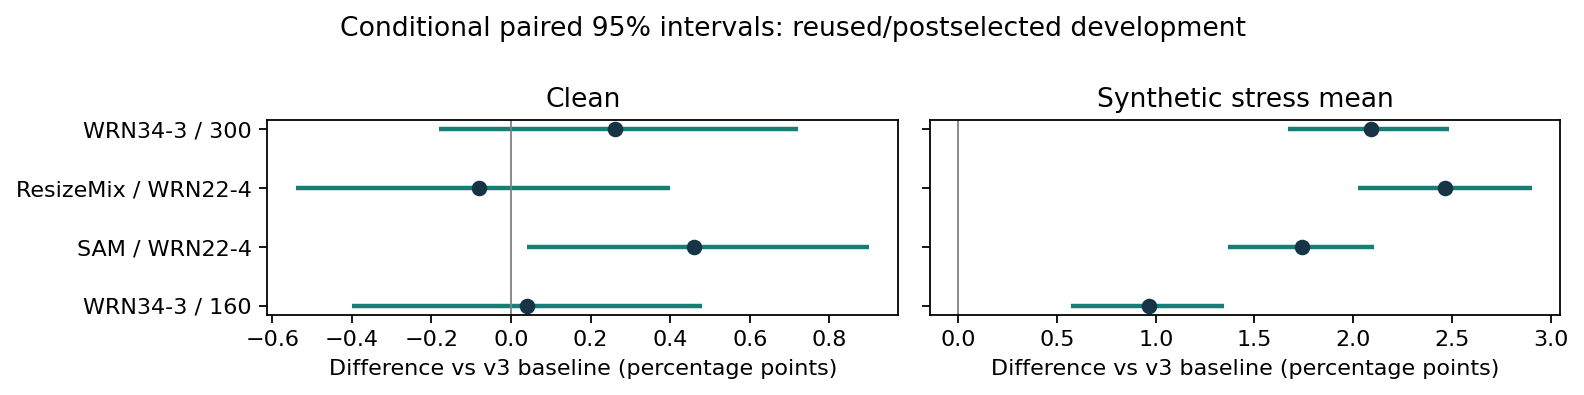

LIMITATION: Research uses the fixed 5,000 development images; the original one-time confirmation belongs only to the original regularized 40k model.
LIMITATION: Stress is the mean of five synthetic views, not hidden-test accuracy. Paired intervals are conditional on fitted models and reused/postselected development.
LIMITATION: All comparison rows use the same local v3 native-BF16 inference context. Training recipes and backends differ; epoch-count causality is not established.
LIMITATION: Only complete canonical scored receipts establish new Kaggle scores; a benchmark, prediction CSV, upload intent or partial repeat does not.
LIMITATION: Full-50k refits have no independent development score; original primary public accuracy and overall observed best remain separate.
ENGINEERING STATUS: SE-WRN22-4/r16 has 4,332,654 total/trainable parameters in CPU construction; no SE accuracy is inferred from model tests.
ENGINEERING STATUS: The fixed averaged SWA candidate is reported with its measur

In [7]:
import hashlib
_followup_snapshot = '{\n  "baseline": {\n    "clean_accuracy": 0.9628,\n    "clean_nll": 0.1221306333810091,\n    "examples": 5000,\n    "policy": "flip",\n    "stress_accuracy": 0.7762800000000001,\n    "training_examples": 40000\n  },\n  "best_new_public": null,\n  "best_observed_public": 0.874,\n  "engineering": [\n    "SE-WRN22-4/r16 has 4,332,654 total/trainable parameters in CPU construction; no SE accuracy is inferred from model tests.",\n    "The fixed averaged SWA candidate is reported with its measured gate outcome; raw-tail control is not substituted for it."\n  ],\n  "limitations": [\n    "Research uses the fixed 5,000 development images; the original one-time confirmation belongs only to the original regularized 40k model.",\n    "Stress is the mean of five synthetic views, not hidden-test accuracy. Paired intervals are conditional on fitted models and reused/postselected development.",\n    "All comparison rows use the same local v3 native-BF16 inference context. Training recipes and backends differ; epoch-count causality is not established.",\n    "Only complete canonical scored receipts establish new Kaggle scores; a benchmark, prediction CSV, upload intent or partial repeat does not.",\n    "Full-50k refits have no independent development score; original primary public accuracy and overall observed best remain separate."\n  ],\n  "official_submissions": [],\n  "original_best_public": 0.874,\n  "original_primary_public": 0.871,\n  "recorded_at": "2026-10-31T21:17:07.553585+00:00",\n  "repository": "https://github.com/Solvement/26-Deep-Learning-Project-1-Kaggle/tree/feat/five-day-autoresearch",\n  "rows": [\n    {\n      "checkpoint_epoch": 152,\n      "checkpoint_sha256": "1787237fb5f4566043843f9008516e911b9a6d867bc6ac4720c52448871c7b9a",\n      "checkpoint_variant": "model",\n      "clean_accuracy": 0.9632,\n      "clean_ci95": [\n        -0.004,\n        0.0048\n      ],\n      "clean_delta": 0.00039999999999995595,\n      "clean_nll": 0.12463519598171115,\n      "delivery_status": "qualified_unscored",\n      "epochs": 160,\n      "gate_passed": true,\n      "id": "wrn34_160",\n      "label": "WRN34-3 / 160",\n      "parameters": 4166298,\n      "policy": "center80_shift20",\n      "precision": "bf16",\n      "repeat_clean_accuracy": 0.9638,\n      "repeat_epochs_completed": 160,\n      "repeat_planned_epochs": 160,\n      "repeat_status": "complete_passed",\n      "repeat_stress_accuracy": 0.79652,\n      "stress_accuracy": 0.78592,\n      "stress_ci95": [\n        0.005679999999999985,\n        0.013480000000000054\n      ],\n      "stress_delta": 0.009639999999999871\n    },\n    {\n      "checkpoint_epoch": 157,\n      "checkpoint_sha256": "5a9771fe26e5b6bd6253a1ddfb2a3187e2087c3348b1569e3585fb6fa6bf07b2",\n      "checkpoint_variant": "model",\n      "clean_accuracy": 0.9674,\n      "clean_ci95": [\n        0.0004,\n        0.009\n      ],\n      "clean_delta": 0.0046000000000000485,\n      "clean_nll": 0.1043639740049839,\n      "delivery_status": "awaiting_repeat",\n      "epochs": 160,\n      "gate_passed": true,\n      "id": "sam",\n      "label": "SAM / WRN22-4",\n      "parameters": 4298970,\n      "policy": "center80_shift20",\n      "precision": "bf16",\n      "repeat_clean_accuracy": null,\n      "repeat_epochs_completed": null,\n      "repeat_planned_epochs": 160,\n      "repeat_status": "not_verified",\n      "repeat_stress_accuracy": null,\n      "stress_accuracy": 0.7936799999999999,\n      "stress_ci95": [\n        0.013640000000000072,\n        0.021080000000000168\n      ],\n      "stress_delta": 0.01739999999999986\n    },\n    {\n      "checkpoint_epoch": 150,\n      "checkpoint_sha256": "c39436412b454f37f030e49beb977ab8e4a6dc60f8027a0e9942c3c3ad534894",\n      "checkpoint_variant": "ema",\n      "clean_accuracy": 0.962,\n      "clean_ci95": [\n        -0.0054,\n        0.004\n      ],\n      "clean_delta": -0.0008000000000000229,\n      "clean_nll": 0.12850121377110482,\n      "delivery_status": "qualified_unscored",\n      "epochs": 160,\n      "gate_passed": true,\n      "id": "resizemix",\n      "label": "ResizeMix / WRN22-4",\n      "parameters": 4298970,\n      "policy": "center80_shift20",\n      "precision": "fp16",\n      "repeat_clean_accuracy": 0.9656,\n      "repeat_epochs_completed": 160,\n      "repeat_planned_epochs": 160,\n      "repeat_status": "complete_passed",\n      "repeat_stress_accuracy": 0.78468,\n      "stress_accuracy": 0.80092,\n      "stress_ci95": [\n        0.02024000000000018,\n        0.029040000000000118\n      ],\n      "stress_delta": 0.024639999999999884\n    },\n    {\n      "checkpoint_epoch": 298,\n      "checkpoint_sha256": "53d8d64df899ebab79ae77144ff36e912c45e65178c0b50bd9af381dc48187bc",\n      "checkpoint_variant": "model",\n      "clean_accuracy": 0.9654,\n      "clean_ci95": [\n        -0.0018,\n        0.0072\n      ],\n      "clean_delta": 0.0026000000000000467,\n      "clean_nll": 0.11753104768097401,\n      "delivery_status": "awaiting_repeat",\n      "epochs": 300,\n      "gate_passed": true,\n      "id": "wrn34_300",\n      "label": "WRN34-3 / 300",\n      "parameters": 4166298,\n      "policy": "center80_shift20",\n      "precision": "fp16",\n      "repeat_clean_accuracy": null,\n      "repeat_epochs_completed": null,\n      "repeat_planned_epochs": 300,\n      "repeat_status": "not_verified",\n      "repeat_stress_accuracy": null,\n      "stress_accuracy": 0.7971600000000001,\n      "stress_ci95": [\n        0.016719000000000095,\n        0.024880000000000204\n      ],\n      "stress_delta": 0.02088000000000001\n    },\n    {\n      "checkpoint_epoch": 200,\n      "checkpoint_sha256": "7d872eb89862f3789b9bd45766f95c60c882ac0a6788c297c9db990f2cd0a26c",\n      "checkpoint_variant": "swa",\n      "clean_accuracy": 0.9572,\n      "clean_ci95": null,\n      "clean_delta": -0.005599999999999938,\n      "clean_nll": 0.1577978115797043,\n      "delivery_status": "not_promoted",\n      "epochs": 200,\n      "gate_passed": false,\n      "id": "swa40",\n      "label": "SWA / WRN34-3",\n      "parameters": 4166298,\n      "policy": "center80_shift20",\n      "precision": "bf16",\n      "repeat_clean_accuracy": null,\n      "repeat_epochs_completed": null,\n      "repeat_planned_epochs": 200,\n      "repeat_status": "not_promoted",\n      "repeat_stress_accuracy": null,\n      "stress_accuracy": 0.8018000000000001,\n      "stress_ci95": null,\n      "stress_delta": 0.025519999999999987\n    }\n  ],\n  "schema": "research_report_followup_v1",\n  "source_summary_sha256": "b3e06bd38571f484c6d90475437162e8849eb65980e982572deb4e166c022d0d",\n  "unscored_receipts_count": 0\n}\n'
_expected_snapshot_sha256 = 'dbd186271cbf032049687ee601dac47900902715efcbbe1fce7cc16f01b07e43'
assert hashlib.sha256(_followup_snapshot.encode('utf-8')).hexdigest() == _expected_snapshot_sha256
followup = json.loads(_followup_snapshot)
print('EXPLORATORY PUBLIC SNAPSHOT:', followup['recorded_at'])
print('Source-summary SHA-256:', followup['source_summary_sha256'])
print('Public snapshot SHA-256:', _expected_snapshot_sha256)
print('Research source:', followup['repository'])
print('Fixed v3 development baseline:', json.dumps(followup['baseline'], indent=2))
for row in followup['rows']:
    print('RESEARCH AGGREGATE:', json.dumps(row, indent=2))
ci_rows = [r for r in followup['rows'] if r['clean_ci95'] is not None and r['stress_ci95'] is not None]
if ci_rows:
    import matplotlib.pyplot as plt
    import io
    from IPython.display import Image, display
    plt.switch_backend('Agg')
    fig, axes = plt.subplots(1, 2, figsize=(10, max(2.5, .48*len(ci_rows))), sharey=True)
    for axis, metric, title in zip(axes, ('clean', 'stress'), ('Clean', 'Synthetic stress mean')):
        for y, row in enumerate(ci_rows):
            lo, hi = row[metric+'_ci95']
            axis.hlines(y, 100*lo, 100*hi, color='#167e75', linewidth=2)
            axis.plot(100*row[metric+'_delta'], y, 'o', color='#173346')
        axis.axvline(0, color='grey', linewidth=.8)
        axis.set(title=title, xlabel='Difference vs v3 baseline (percentage points)')
        axis.set_yticks(range(len(ci_rows)), [r['label'] for r in ci_rows])
    fig.suptitle('Conditional paired 95% intervals: reused/postselected development')
    fig.tight_layout()
    figure_buffer = io.BytesIO()
    fig.savefig(figure_buffer, format='png', dpi=160, bbox_inches='tight')
    display(Image(data=figure_buffer.getvalue()))
    plt.close(fig)
for statement in followup['limitations']:
    print('LIMITATION:', statement)
for statement in followup['engineering']:
    print('ENGINEERING STATUS:', statement)
print('The original 96.64% confirmation belongs only to regularized trained on 40,000 images. Not reused for research.')

## Follow-on official scoring

Only validated completed official receipts appear below. Benchmark completion, a CSV, an upload intent and pending scoring do not establish a public score. Original primary, original best, newly scored research best and best observed across both are distinct. Public selection does not establish the private winner.

In [8]:
print('Original primary public score:', accuracy(followup['original_primary_public']))
print('Best original public score:', accuracy(followup['original_best_public']))
print('Best newly scored research public score:', accuracy(followup['best_new_public']))
print('Best observed public score (original + research):', accuracy(followup['best_observed_public']))
print('Unscored receipt records:', followup['unscored_receipts_count'])
print('Newly scored research receipts:', len(followup['official_submissions']))
for receipt in followup['official_submissions']:
    print('OFFICIAL RESEARCH RECEIPT:', json.dumps(receipt, indent=2))
if not followup['official_submissions']:
    print('No newly scored research submission in this reporting snapshot.')
print('Missing private scores remain unknown; no original confirmation result is assigned to these entries.')

Original primary public score: 87.10%
Best original public score: 87.40%
Best newly scored research public score: Pending
Best observed public score (original + research): 87.40%
Unscored receipt records: 0
Newly scored research receipts: 0
No newly scored research submission in this reporting snapshot.
Missing private scores remain unknown; no original confirmation result is assigned to these entries.


## Reproduction and artifact policy
Follow the repository README to prepare official competition data, train the chosen configuration, validate predictions, and generate this report. Data, weights and prediction files stay private and are excluded from Git. The course staff can inspect the saved manifests, checksums and logs.

## References
1. [He, Zhang, Ren and Sun (2016). Deep Residual Learning for Image Recognition.](https://arxiv.org/abs/1512.03385)
2. [Zagoruyko and Komodakis (2016). Wide Residual Networks.](https://arxiv.org/abs/1605.07146)
3. [Zhang et al. (2018). mixup: Beyond Empirical Risk Minimization.](https://arxiv.org/abs/1710.09412)
4. [DeVries and Taylor (2017). Improved Regularization of Convolutional Neural Networks with Cutout.](https://arxiv.org/abs/1708.04552)
5. [Loshchilov and Hutter (2017). SGDR: Stochastic Gradient Descent with Warm Restarts. Cosine schedule reference; this project need not use restarts.](https://arxiv.org/abs/1608.03983)
6. [Cubuk, Zoph, Shlens and Le (2019). RandAugment: Practical automated data augmentation with a reduced search space.](https://arxiv.org/abs/1909.13719)
7. [Izmailov et al. (2018). Averaging Weights Leads to Wider Optima and Better Generalization.](https://arxiv.org/abs/1803.05407)
8. [Foret et al. (2021). Sharpness-Aware Minimization for Efficiently Improving Generalization.](https://arxiv.org/abs/2010.01412)
9. [Yun et al. (2019). CutMix: Regularization Strategy to Train Strong Classifiers with Localizable Features.](https://arxiv.org/abs/1905.04899)
10. [Qin et al. (2020). ResizeMix: Mixing Data with Preserved Object Information and True Labels.](https://arxiv.org/abs/2012.11101)
11. [Shanmugam et al. (2021). Better Aggregation in Test-Time Augmentation.](https://arxiv.org/abs/2011.11156)
12. [Hu, Shen and Sun (2018). Squeeze-and-Excitation Networks. Engineering-only candidate reference.](https://arxiv.org/abs/1709.01507)